In [1]:
# 1. Setup
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

REPO = os.path.abspath("../..")
sys.path.insert(0, REPO)
DATA_DIR = f"{REPO}/data"
RESULTS_DIR = f"{REPO}/results"
from evaluate import load_data, reconstruction_errors, evaluate, compare_percentiles, per_feature_errors

SEED = 42
keras.utils.set_random_seed(SEED)

X_train, X_val, X_test, y_test, attack_test = load_data(DATA_DIR)
FEATURES = json.load(open(f"{DATA_DIR}/config.json"))["features"]

I0000 00:00:1795279213.984613     145 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795279216.026868     145 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)


In [2]:
# 2. Model (Person 1's final architecture + input noise)
HIDDEN = [48]
LATENT = 32
DROPOUT = 0.0
L2 = 1e-6
LR = 5e-4

def build_dae(noise):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.L2(L2)

    inputs = keras.Input(shape=(40,))
    x = layers.GaussianNoise(noise, seed=SEED)(inputs)
    for units in HIDDEN:
        x = layers.Dense(units, activation="relu", kernel_regularizer=reg)(x)
        x = layers.Dropout(DROPOUT, seed=SEED)(x)
    x = layers.Dense(LATENT, activation="linear", kernel_regularizer=reg, name="latent")(x)
    for units in reversed(HIDDEN):
        x = layers.Dense(units, activation="relu", kernel_regularizer=reg)(x)
        x = layers.Dropout(DROPOUT, seed=SEED)(x)
    outputs = layers.Dense(40, activation="linear")(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss="mse")
    return model

build_dae(0.1).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 48)             │         1,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 48)             │         1,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 40)             │         1,960 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,080 (27.66 KB)

 Trainable params: 7,080 (27.66 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# 3. Fake anomalies for tuning (made from validation rows, no test data)
rng = np.random.default_rng(SEED)
X_fake = X_val[:5000].copy()
for row in X_fake:
    cols = rng.choice(40, size=3, replace=False)
    row[cols] = rng.uniform(0, 1, size=3)

In [4]:
# 4. Tuning: train one model per noise level (0.0 = Vanilla AE)
NOISE_LEVELS = [0.0, 0.05, 0.1, 0.2]
models, histories, rows = {}, {}, []

for noise in NOISE_LEVELS:
    model = build_dae(noise)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h = model.fit(X_train, X_train, validation_data=(X_val, X_val),
                  epochs=200, batch_size=512, callbacks=[stop], verbose=0)

    val_err = reconstruction_errors(model, X_val)
    thr = np.percentile(val_err, 99)
    fake_recall = (reconstruction_errors(model, X_fake) > thr).mean()

    models[noise] = model
    histories[noise] = h.history
    rows.append({"noise": noise, "epochs": len(h.history["loss"]),
                 "val_mse": val_err.mean(), "fake_recall": fake_recall})
    print(rows[-1])

tuning = pd.DataFrame(rows)
tuning

{'noise': 0.0, 'epochs': 125, 'val_mse': np.float32(1.1022008e-05), 'fake_recall': np.float64(0.9546)}


{'noise': 0.05, 'epochs': 51, 'val_mse': np.float32(0.00015206783), 'fake_recall': np.float64(0.964)}


{'noise': 0.1, 'epochs': 52, 'val_mse': np.float32(0.00042205682), 'fake_recall': np.float64(0.9418)}


{'noise': 0.2, 'epochs': 29, 'val_mse': np.float32(0.0013405533), 'fake_recall': np.float64(0.8298)}


,noise,epochs,val_mse,fake_recall
0,0.00,125,0.000011,0.9546
1,0.05,51,0.000152,0.9640
2,0.10,52,0.000422,0.9418
3,0.20,29,0.001341,0.8298


Best noise: 0.05


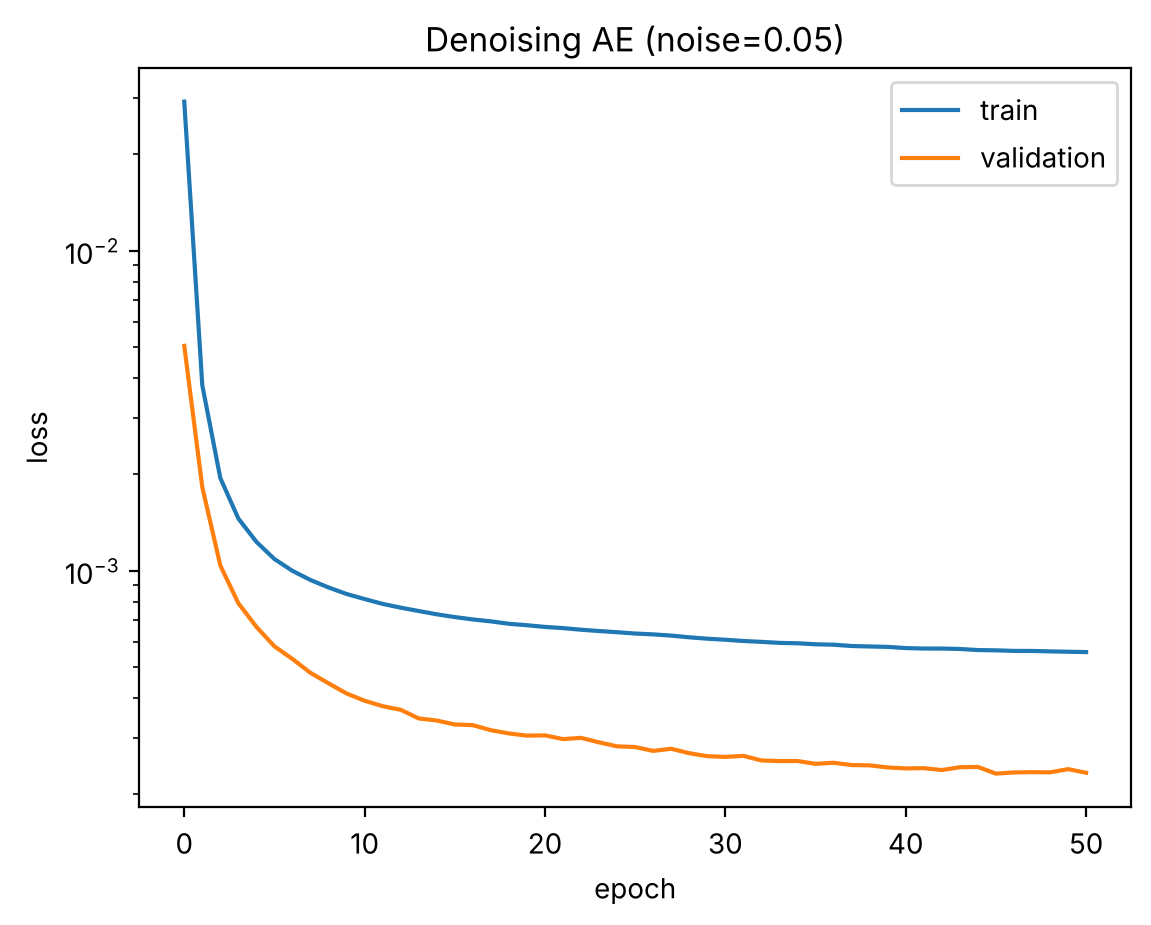

In [5]:
# 5. Pick the best noise level (highest fake_recall)
best_noise = float(tuning[tuning["noise"] > 0].sort_values("fake_recall", ascending=False).iloc[0]["noise"])
model = models[best_noise]
print("Best noise:", best_noise)

h = histories[best_noise]
plt.plot(h["loss"], label="train")
plt.plot(h["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.yscale("log")
plt.title(f"Denoising AE (noise={best_noise})"); plt.legend()
plt.show()


===== Denoising AE =====
Threshold (P99 of validation scores): 0.00105257
          roc_auc: 0.9614
           pr_auc: 0.9025
               f1: 0.8396
        precision: 0.8294
           recall: 0.8500
 false_alarm_rate: 0.0246

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   36683     924
Attack     793    4493

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.033
MQTT Malformed Data      300  0.247
Recon VulScan            300  0.510
Recon PingSweep          186  0.532
Recon OSScan             300  0.887
Recon PortScan           300  0.970
DDoS TCP Flood           300  1.000
DoS SYN Flood            300  1.000
DoS ICMP Flood           300  1.000
DoS TCP Flood            300  1.000
DoS UDP Flood            300  1.000
MQTT DDoS Publish Flood  300  1.000
DDoS UDP Flood           300  1.000
DDoS ICMP Flood          300  1.000
DDoS SYN Flood           300  1.0

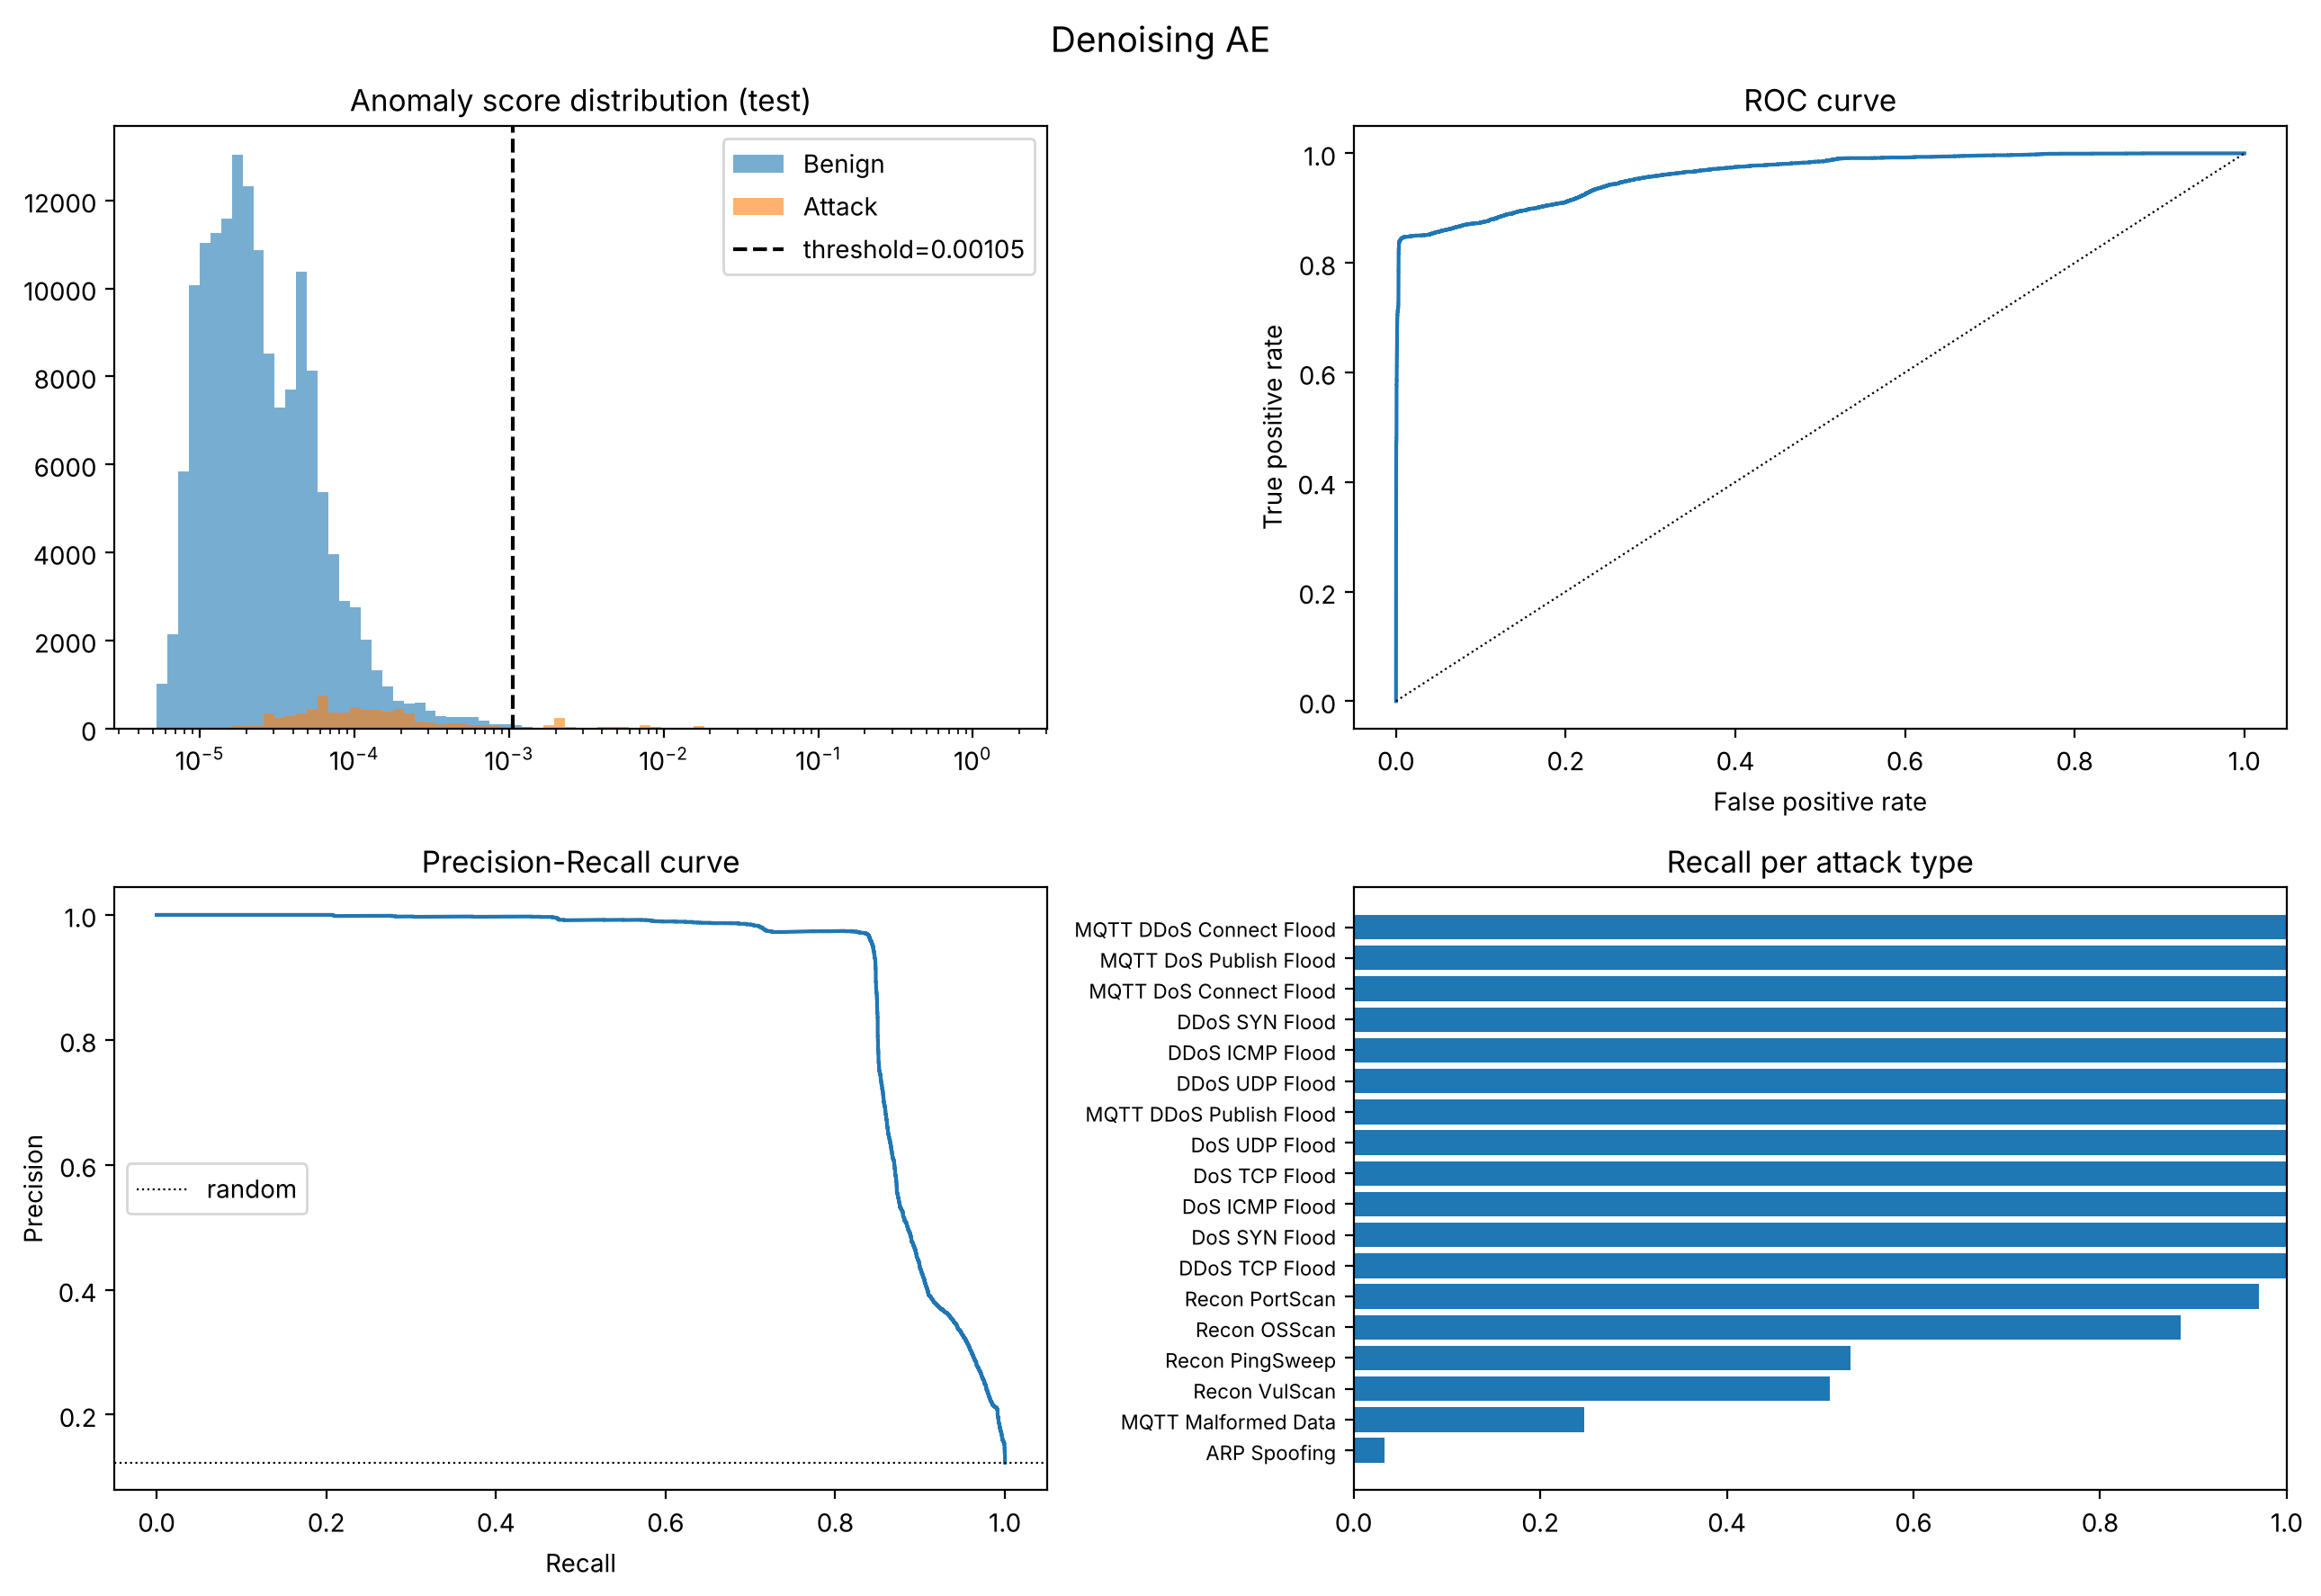


Saved to /home/claude/ext/iomt-anomaly-detection/results/results.csv
 percentile  threshold     f1  recall  false_alarm_rate
    95.0000     0.0005 0.6778  0.8733            0.0989
    99.0000     0.0011 0.8396  0.8500            0.0246
    99.5000     0.0018 0.8983  0.8367            0.0037


,percentile,threshold,f1,recall,false_alarm_rate
0,95.0,0.000543,0.677777,0.873250,0.098891
1,99.0,0.001053,0.839578,0.849981,0.024570
2,99.5,0.001763,0.898345,0.836739,0.003670


In [6]:
# 6. Final evaluation on test
val_scores = reconstruction_errors(model, X_val)
test_scores = reconstruction_errors(model, X_test)
res = evaluate(test_scores, y_test, attack_test, val_scores,
               model_name="Denoising AE", person="2", save_dir=RESULTS_DIR)
compare_percentiles(test_scores, y_test, val_scores)

In [7]:
# 7. Did the noise help? Compare with the same model without noise
vanilla = models[0.0]
res_vanilla = evaluate(reconstruction_errors(vanilla, X_test), y_test, attack_test,
                       reconstruction_errors(vanilla, X_val),
                       model_name="Vanilla AE (no noise)", plot=False)

metrics = ["roc_auc", "pr_auc", "f1", "false_alarm_rate"]
pca = {"roc_auc": 0.938, "pr_auc": 0.835, "f1": 0.761, "false_alarm_rate": 0.0037}
pd.DataFrame({
    "PCA": pca,
    "Vanilla AE": {m: res_vanilla[m] for m in metrics},
    "Denoising AE": {m: res[m] for m in metrics},
}).round(4)


===== Vanilla AE (no noise) =====
Threshold (P99 of validation scores): 0.000101069
          roc_auc: 0.9513
           pr_auc: 0.8997
               f1: 0.8876
        precision: 0.9420
           recall: 0.8392
 false_alarm_rate: 0.0073

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   37334     273
Attack     850    4436

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.017
MQTT Malformed Data      300  0.183
Recon VulScan            300  0.420
Recon PingSweep          186  0.522
Recon OSScan             300  0.890
Recon PortScan           300  0.953
DDoS TCP Flood           300  1.000
DoS SYN Flood            300  1.000
DoS ICMP Flood           300  1.000
DoS TCP Flood            300  1.000
DoS UDP Flood            300  1.000
MQTT DDoS Publish Flood  300  1.000
DDoS UDP Flood           300  1.000
DDoS ICMP Flood          300  1.000
DDoS SYN Flood         

,PCA,Vanilla AE,Denoising AE
roc_auc,0.9380,0.9513,0.9614
pr_auc,0.8350,0.8997,0.9025
f1,0.7610,0.8876,0.8396
false_alarm_rate,0.0037,0.0073,0.0246


In [8]:
# 8. Hard attacks (where PCA fails)
hard = [a for a in res["per_attack_recall"] if any(k in a for k in ["ARP", "MQTT", "PingSweep", "VulScan"])]
pd.DataFrame({
    "Vanilla AE": {a: res_vanilla["per_attack_recall"][a] for a in hard},
    "Denoising AE": {a: res["per_attack_recall"][a] for a in hard},
})

,Vanilla AE,Denoising AE
ARP Spoofing,0.0167,0.0333
MQTT Malformed Data,0.1833,0.2467
Recon VulScan,0.4200,0.5100
Recon PingSweep,0.5215,0.5323
MQTT DDoS Publish Flood,1.0000,1.0000
MQTT DoS Connect Flood,1.0000,1.0000
MQTT DoS Publish Flood,1.0000,1.0000
MQTT DDoS Connect Flood,1.0000,1.0000


In [9]:
# 9. Save, load, and check the scores are identical
model.save("denoising_ae.keras")
loaded = keras.models.load_model("denoising_ae.keras")
assert np.allclose(reconstruction_errors(loaded, X_test), test_scores, atol=1e-6)

json.dump({"threshold": res["threshold"], "noise": best_noise}, open("threshold.json", "w"), indent=2)
print("Saved and reloaded. Threshold:", res["threshold"])

Saved and reloaded. Threshold: 0.0010525660100392956


In [10]:
# 10. Inference
THRESHOLD = res["threshold"]

def predict(X):
    err = per_feature_errors(loaded, X)
    scores = err.mean(axis=1)
    top = [[FEATURES[j] for j in np.argsort(-e)[:3]] for e in err]
    return [{"score": float(s), "is_anomaly": bool(s > THRESHOLD), "top_features": t}
            for s, t in zip(scores, top)]

pd.DataFrame(predict(X_test[:5]))

,score,is_anomaly,top_features
0,0.000026,False,"[max, ack_flag_number, avg]"
1,0.017486,True,"[ack_flag_number, tcp, udp]"
2,0.000109,False,"[variance, covariance, radius]"
3,0.003678,True,"[syn_flag_number, number, iat]"
4,0.000025,False,"[rst_count, covariance, rate]"
